Name: Kriti Bhattacharya 
Github Username: Kritiin5 
USC ID: 3277100685

In [47]:
from pathlib import Path
import pandas as pd
import numpy as np

data_folder = Path('../data/AReM')

activities = [
    'bending1',
    'bending2',
    'cycling',
    'lying',
    'sitting',
    'standing',
    'walking'
]

train_files = []
test_files = []
for activity in activities:
    folder = data_folder / activity
    
    for file in folder.glob('dataset*.csv'):
        number = int(file.stem.replace('dataset', ''))
        
        if activity in ['bending1', 'bending2']:
            is_test_file = number <= 2
        else:
            is_test_file = number <= 3
        
        if is_test_file:
            test_files.append(file)
        else:
            train_files.append(file)

print("Number of training instances:", len(train_files))
print("Number of testing instances:", len(test_files))
print("Total number of instances:", len(train_files) + len(test_files))


Number of training instances: 69
Number of testing instances: 19
Total number of instances: 88


In [48]:
def extract_features(file):
    
    column_names = [
        'time',
        'avg_rss12',
        'var_rss12',
        'avg_rss13',
        'var_rss13',
        'avg_rss23',
        'var_rss23'
    ]
    
    # This file uses spaces instead of commas
    if file.parent.name == 'bending2' and file.name == 'dataset4.csv':
        data = pd.read_csv(file, skiprows=5, sep=r'\s+', header=None,names=column_names)
    
    # All other files use commas
    else:
        data = pd.read_csv(file, skiprows=4,usecols=range(7),engine='python')
        data.columns = data.columns.str.strip()
    
    row = {}
    
    for i in range(1, 7):
        values = pd.to_numeric(data.iloc[:, i], errors='coerce').dropna()
        
        row[f'min{i}'] = values.min()
        row[f'max{i}'] = values.max()
        row[f'mean{i}'] = values.mean()
        row[f'median{i}'] = values.median()
        row[f'std{i}'] = values.std()
        row[f'1st_quart{i}'] = values.quantile(0.25)
        row[f'3rd_quart{i}'] = values.quantile(0.75)
    
    return row

# extract features from files
all_rows = []

for file in train_files:
    row = extract_features(file)
    row['activity'] = file.parent.name
    row['dataset'] = int(file.stem.replace('dataset', ''))
    row['set'] = 'train'
    all_rows.append(row)

for file in test_files:
    row = extract_features(file)
    row['activity'] = file.parent.name
    row['dataset'] = int(file.stem.replace('dataset', ''))
    row['set'] = 'test'
    all_rows.append(row)


feature_table = pd.DataFrame(all_rows)



feature_columns = []

for i in range(1, 7):
    feature_columns.extend([f'min{i}', f'max{i}', f'mean{i}', f'median{i}', f'std{i}', f'1st_quart{i}', f'3rd_quart{i}'])

feature_table = feature_table[
    ['activity', 'dataset', 'set'] + feature_columns
]

feature_table.head()

,activity,dataset,set,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,bending1,7,train,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,...,3.318301,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83
1,bending1,6,train,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,...,2.488862,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87
2,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00
3,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50
4,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94


2a. i.

In [49]:
train_data = feature_table[
    feature_table['set'] == 'train'
].copy()

train_data['class'] = np.where(
    train_data['activity'].isin(['bending1', 'bending2']),
    'bending',
    'other'
)

print(train_data['class'].value_counts())

class
other      60
bending     9
Name: count, dtype: int64


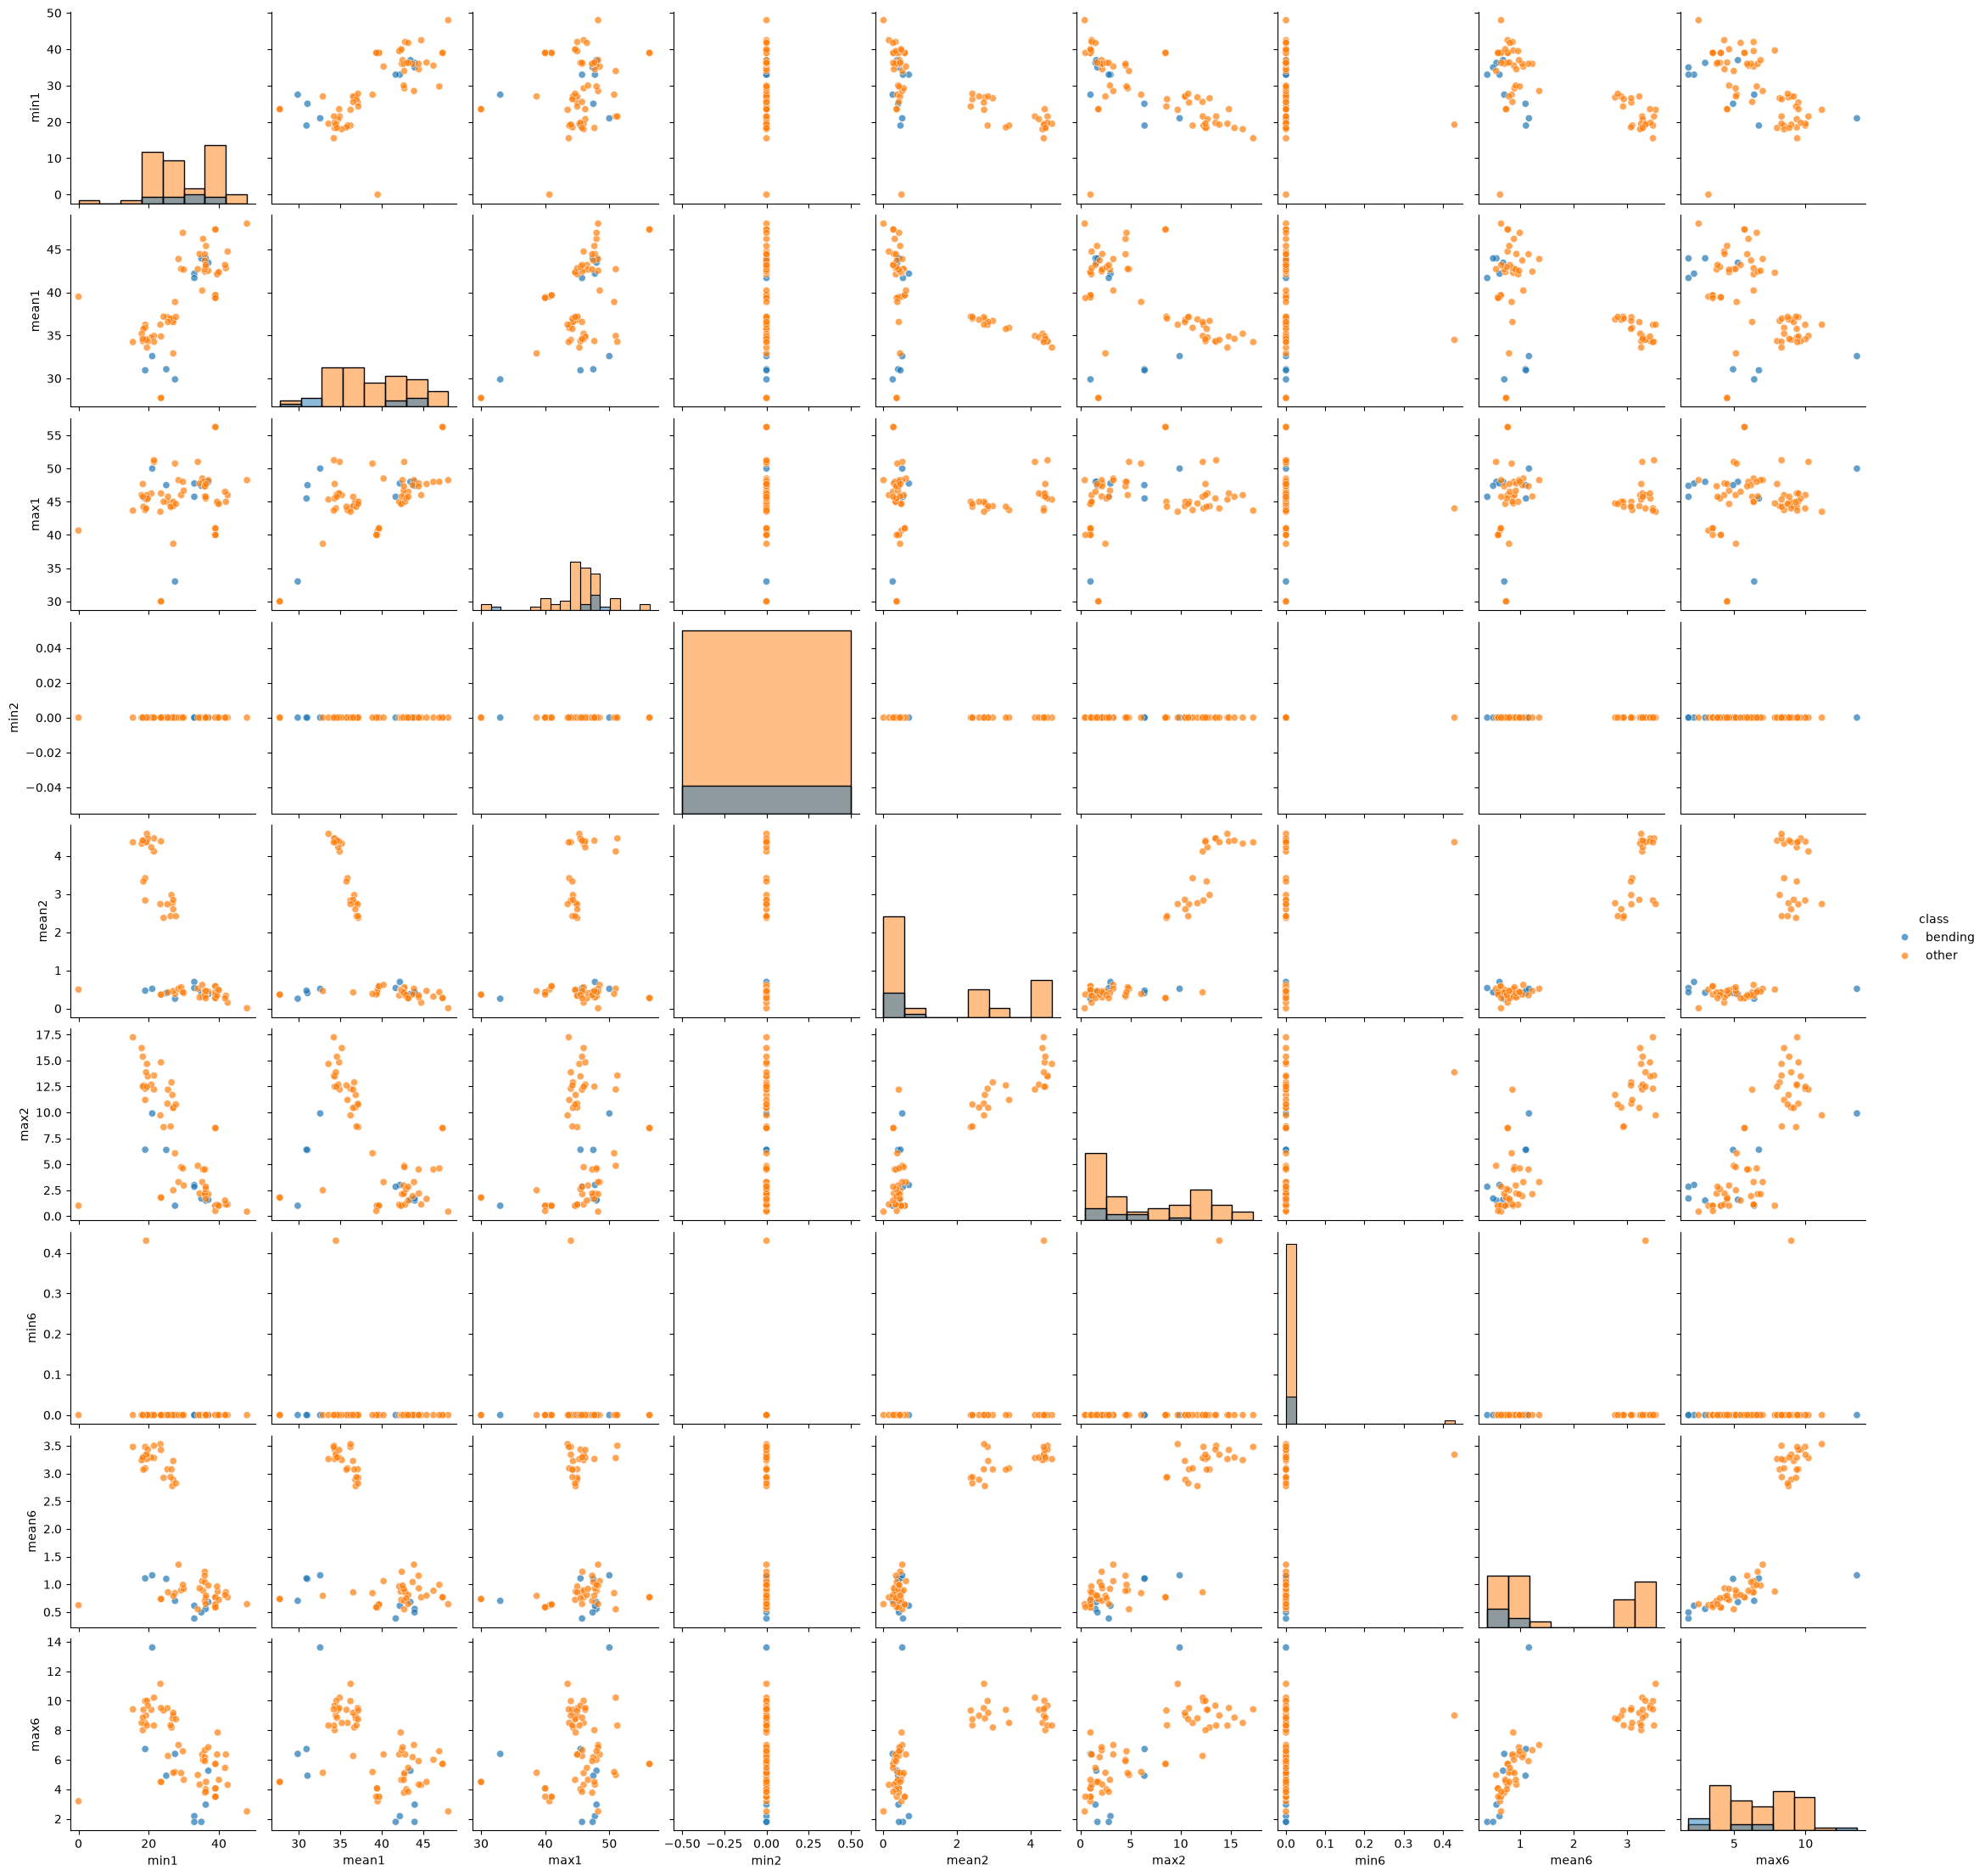

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt

selected_features = [
    'min1', 'mean1', 'max1',
    'min2', 'mean2', 'max2',
    'min6', 'mean6', 'max6'
]

sns.pairplot(
    train_data,
    vars=selected_features,
    hue='class',
    diag_kind='hist',
    plot_kws={
        'alpha': 0.7,
        's': 35
    }
)

plt.show()

The two classes have some separation, but they also overlap. The mean and maximum features from time series 2 and 6 seem useful for separating bending from the other activities. The minimum features from time series 2 and 6 are not very useful because most of their values are zero.

There are also fewer bending instances than other activity instances.

2a. ii.

In [51]:
def read_file(file):
    column_names = [
        'time',
        'avg_rss12',
        'var_rss12',
        'avg_rss13',
        'var_rss13',
        'avg_rss23',
        'var_rss23'
    ]

    if file.parent.name == 'bending2' and file.name == 'dataset4.csv':
        data = pd.read_csv(file, skiprows=5,sep=r'\s+', header=None, names=column_names)
    else:
        data = pd.read_csv(file, skiprows=4, usecols=range(7), engine='python')
        data.columns = data.columns.str.strip()

    return data

In [52]:
def extract_two_parts(file):
    data = read_file(file)

    middle = len(data) // 2

    parts = [
        data.iloc[:middle],
        data.iloc[middle:]
    ]

    row = {}

    for part_number, part in enumerate(parts, start=1):
        for series_number in [1, 2, 6]:
            values = pd.to_numeric(
                part.iloc[:, series_number],
                errors='coerce'
            ).dropna()

            row[f'min{series_number}_part{part_number}'] = values.min()
            row[f'mean{series_number}_part{part_number}'] = values.mean()
            row[f'max{series_number}_part{part_number}'] = values.max()

    return row

In [53]:
two_part_rows = []

for file in train_files:
    row = extract_two_parts(file)

    row['activity'] = file.parent.name

    if file.parent.name in ['bending1', 'bending2']:
        row['class'] = 'bending'
    else:
        row['class'] = 'other'

    two_part_rows.append(row)

two_part_data = pd.DataFrame(two_part_rows)

print(two_part_data.shape)
two_part_data.head()

(69, 20)


,min1_part1,mean1_part1,max1_part1,min2_part1,mean2_part1,max2_part1,min6_part1,mean6_part1,max6_part1,min1_part2,mean1_part2,max1_part2,min2_part2,mean2_part2,max2_part2,min6_part2,mean6_part2,max6_part2,activity,class
0,36.67,43.486208,45.00,0.0,0.378667,1.30,0.0,0.524875,2.28,36.25,44.452042,48.00,0.0,0.447583,1.50,0.0,0.585750,2.96,bending1,bending
1,39.00,44.117042,48.00,0.0,0.250042,1.30,0.0,0.815417,5.26,37.00,42.792875,46.50,0.0,0.506125,1.58,0.0,0.543875,4.06,bending1,bending
2,33.75,43.278875,47.75,0.0,0.673292,3.00,0.0,0.640958,1.53,33.00,41.080750,46.00,0.0,0.718792,2.86,0.0,0.586083,2.18,bending1,bending
3,33.00,41.621208,45.75,0.0,0.623083,2.83,0.0,0.419083,1.79,39.25,41.734917,43.67,0.0,0.448875,1.12,0.0,0.347500,1.50,bending1,bending
4,36.50,44.057167,46.50,0.0,0.381042,1.50,0.0,0.598250,1.79,35.00,43.851833,47.40,0.0,0.471458,1.70,0.0,0.388333,1.50,bending1,bending


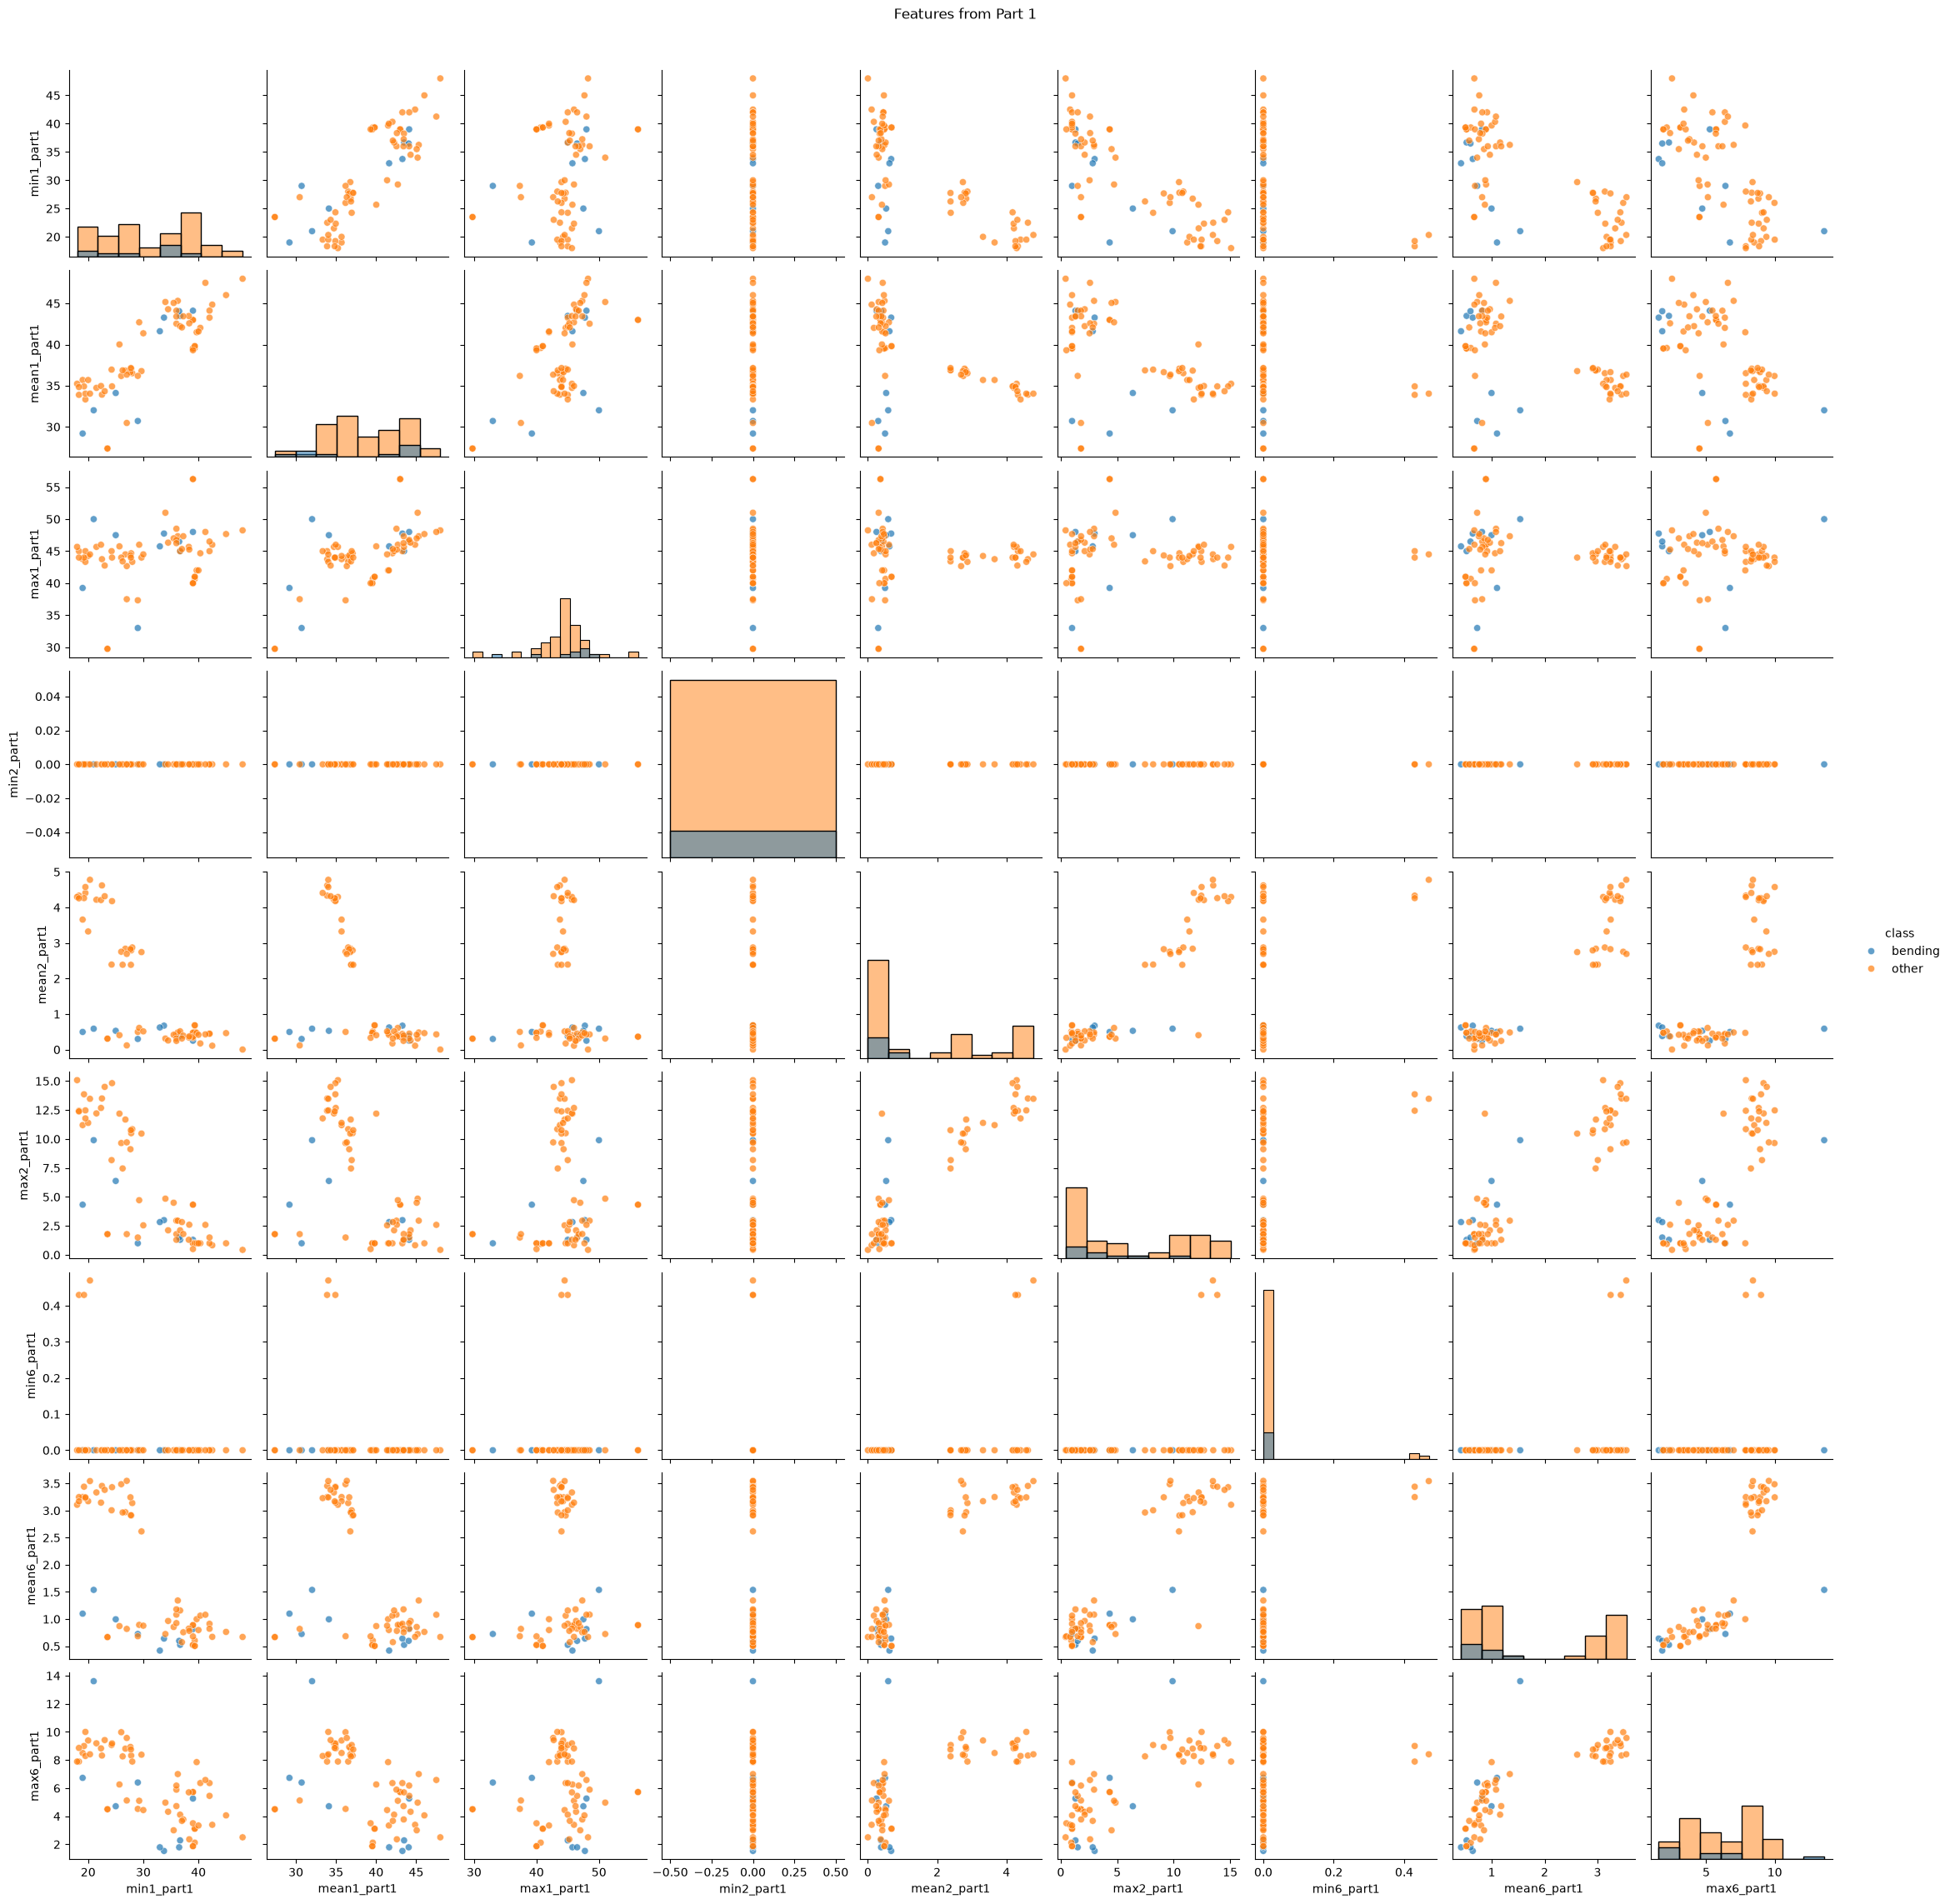

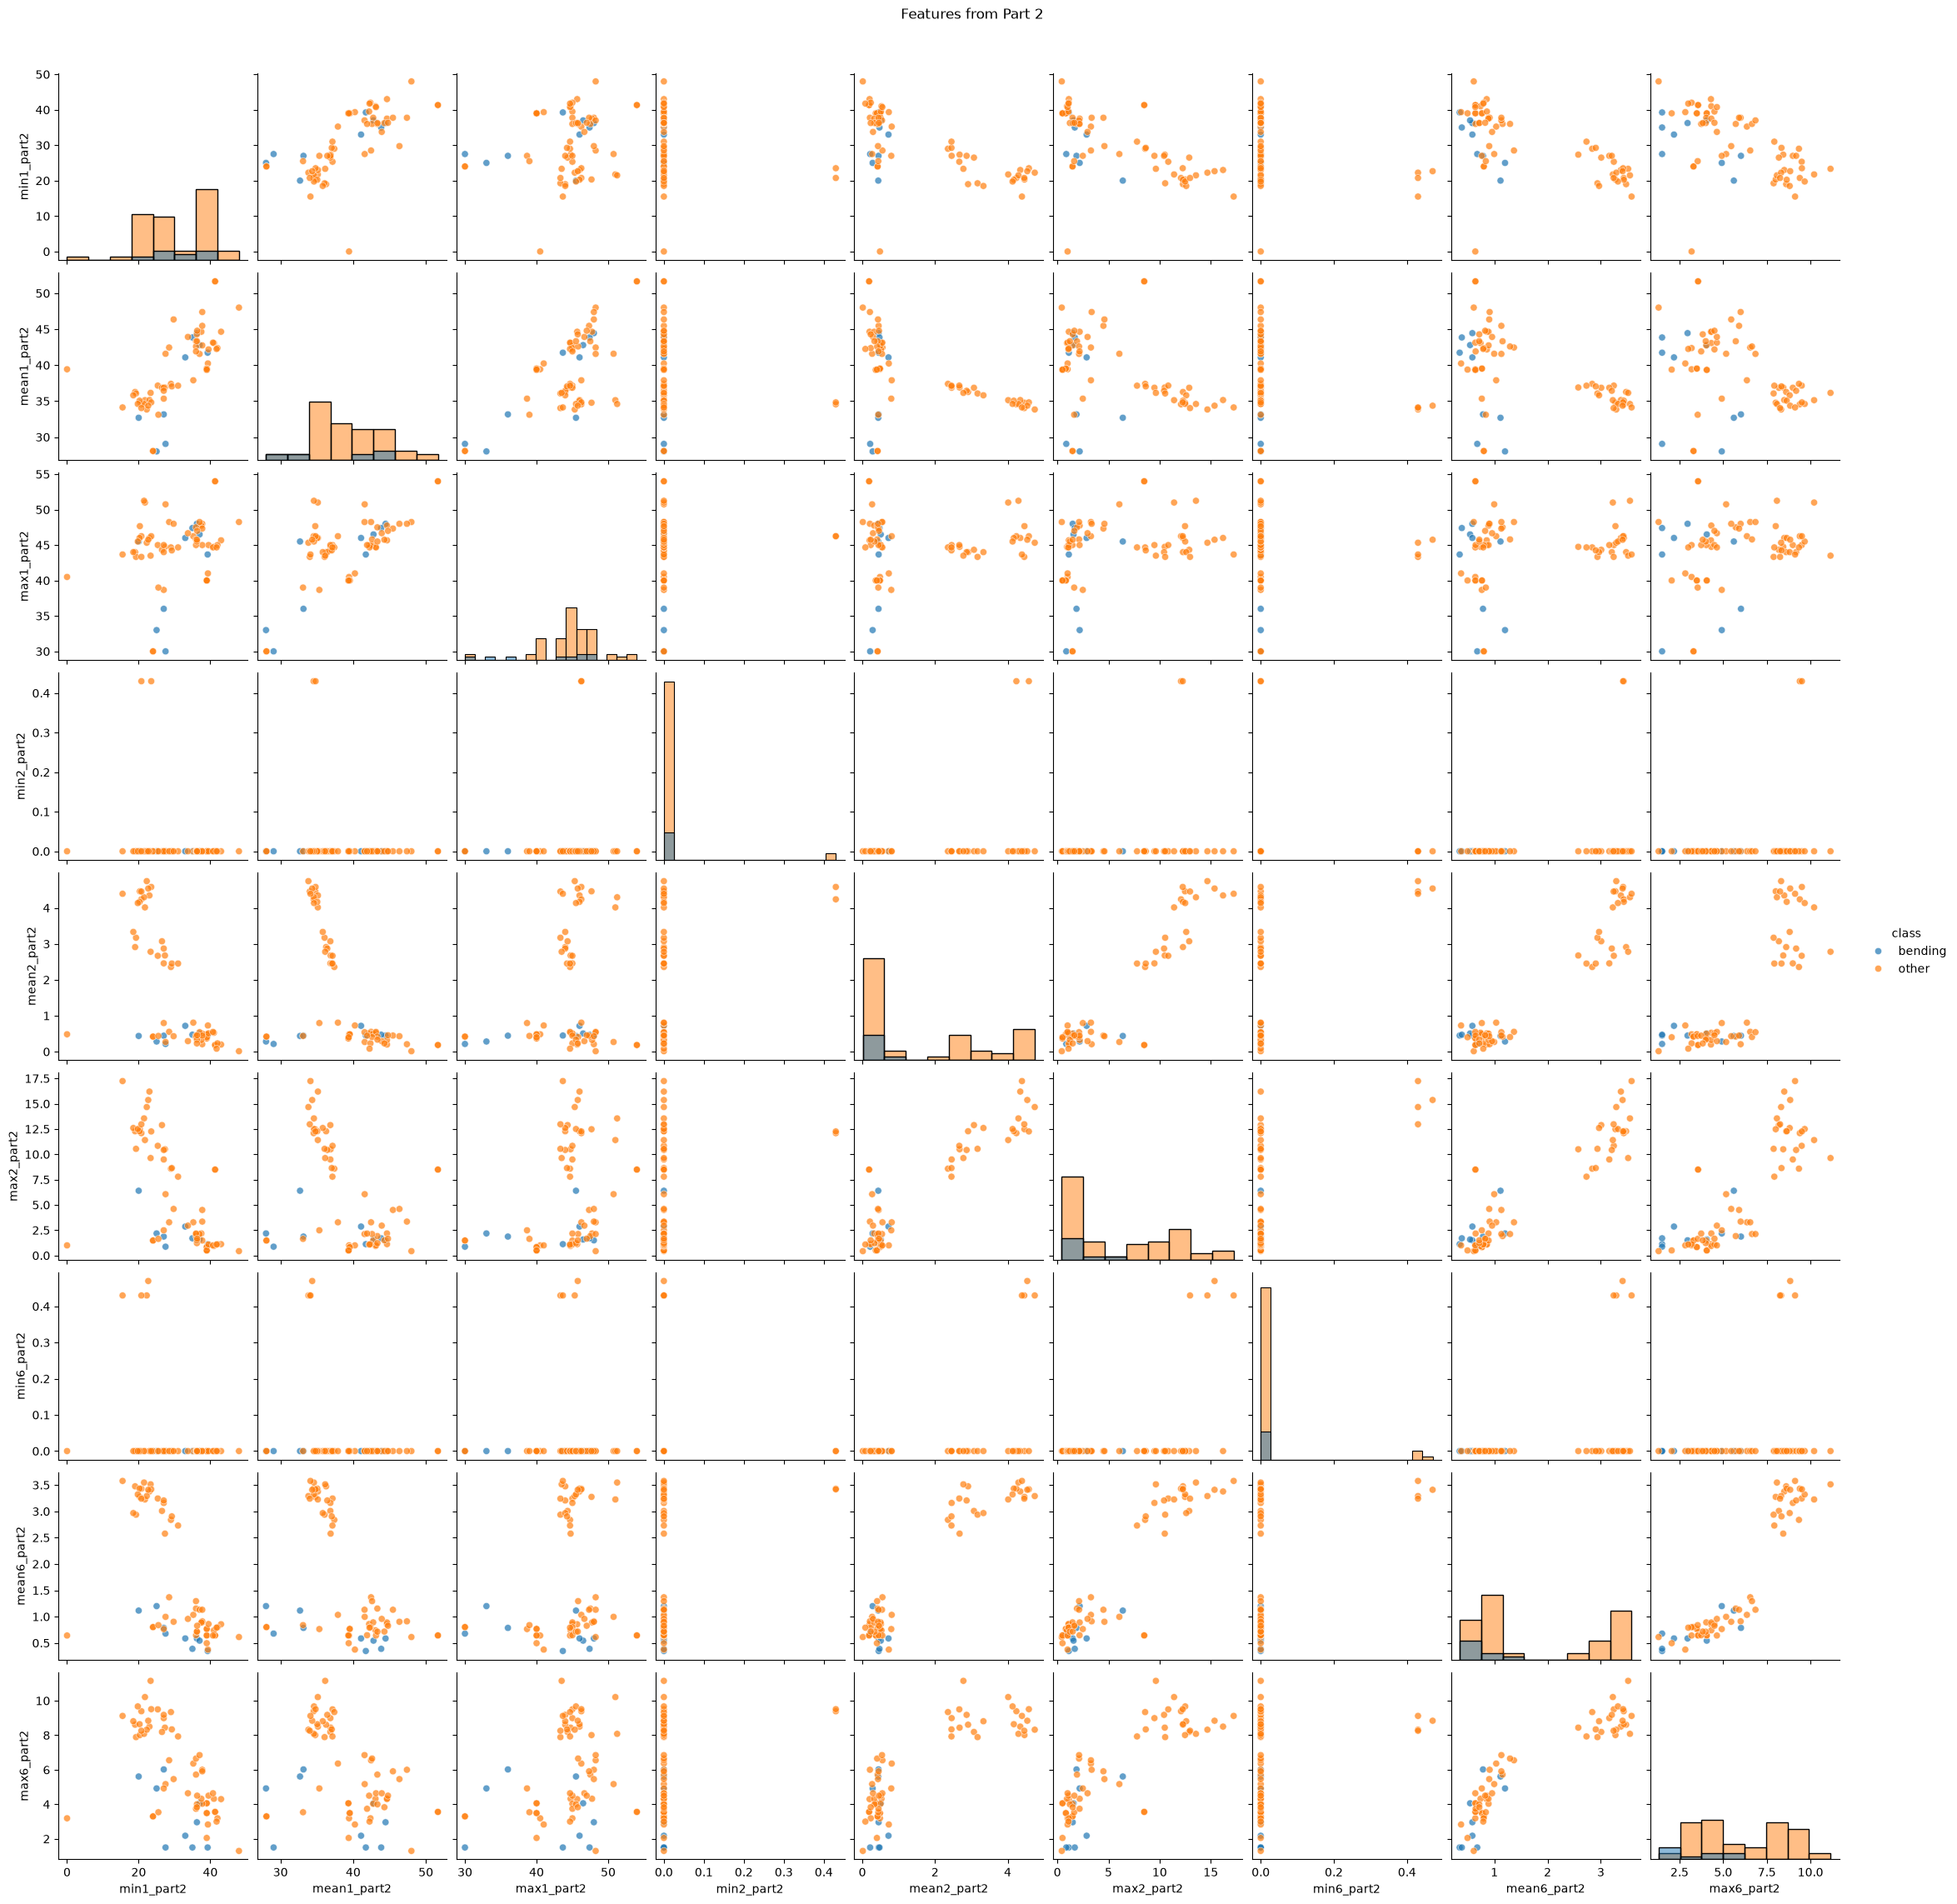

In [54]:
for part_number in [1, 2]:
    part_features = []

    for series_number in [1, 2, 6]:
        part_features.extend([
            f'min{series_number}_part{part_number}',
            f'mean{series_number}_part{part_number}',
            f'max{series_number}_part{part_number}'
        ])

    plot = sns.pairplot(
        two_part_data,
        vars=part_features,
        hue='class',
        diag_kind='hist',
        plot_kws={'alpha': 0.7, 's': 35}
    )

    plot.fig.suptitle(
        f'Features from Part {part_number}',
        y=1.02
    )

    plt.show()

The two parts show similar patterns. The mean and maximum features from time series 2 and 6 provide some separation between bending and the other activities. However, the two classes still overlap. Splitting the time series provides more detailed information than using the entire series.

2a. iii.

In [55]:
def extract_l_parts(file, l):
    data = read_file(file)

    # Split the row numbers into l approximately equal parts
    row_groups = np.array_split(np.arange(len(data)), l)

    features = {}

    for part_number, rows in enumerate(row_groups, start=1):
        part = data.iloc[rows]

        for series_number in range(1, 7):
            values = pd.to_numeric(
                part.iloc[:, series_number],
                errors='coerce'
            ).dropna()

            features[f'min{series_number}_part{part_number}'] = values.min()
            features[f'max{series_number}_part{part_number}'] = values.max()
            features[f'mean{series_number}_part{part_number}'] = values.mean()
            features[f'median{series_number}_part{part_number}'] = values.median()
            features[f'std{series_number}_part{part_number}'] = values.std()
            features[f'1st_quart{series_number}_part{part_number}'] = values.quantile(0.25)
            features[f'3rd_quart{series_number}_part{part_number}'] = values.quantile(0.75)

    return features

In [56]:
def make_training_data(l):
    rows = []
    labels = []

    for file in train_files:
        features = extract_l_parts(file, l)
        rows.append(features)

        if file.parent.name in ['bending1', 'bending2']:
            labels.append(1)
        else:
            labels.append(0)

    X = pd.DataFrame(rows)
    y = np.array(labels)

    return X, y


X_check, y_check = make_training_data(2)

print("Shape:", X_check.shape)
print("Bending instances:", sum(y_check == 1))
print("Other instances:", sum(y_check == 0))

Shape: (69, 84)
Bending instances: 9
Other instances: 60


In [57]:
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []
models = {}

for l in range(1, 21):
    X, y = make_training_data(l)

    logistic_model = Pipeline([
        ('scale', StandardScaler()),
        ('model', LogisticRegression(
            C=1000000,
            max_iter=2000
        ))
    ])

    selector = RFECV(
        estimator=logistic_model,
        step=1,
        min_features_to_select=1,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1,
        importance_getter='named_steps.model.coef_'
    )

    selector.fit(X, y)

    best_score = selector.cv_results_['mean_test_score'].max()
    best_p = selector.n_features_

    results.append({
        'l': l,
        'p': best_p,
        'CV Accuracy': best_score
    })

    models[l] = {
        'selector': selector,
        'features': X.columns
    }

    print(
        "l =", l,
        "| p =", best_p,
        "| CV Accuracy =", round(best_score, 4)
    )

l = 1 | p = 12 | CV Accuracy = 0.9857
l = 2 | p = 10 | CV Accuracy = 0.9714
l = 3 | p = 2 | CV Accuracy = 0.9571
l = 4 | p = 4 | CV Accuracy = 0.9714
l = 5 | p = 1 | CV Accuracy = 0.9571
l = 6 | p = 2 | CV Accuracy = 0.9714
l = 7 | p = 24 | CV Accuracy = 0.9571
l = 8 | p = 10 | CV Accuracy = 0.9571
l = 9 | p = 7 | CV Accuracy = 0.9714
l = 10 | p = 12 | CV Accuracy = 0.9857
l = 11 | p = 3 | CV Accuracy = 0.9714
l = 12 | p = 4 | CV Accuracy = 0.9857
l = 13 | p = 14 | CV Accuracy = 0.9429
l = 14 | p = 8 | CV Accuracy = 0.9714
l = 15 | p = 27 | CV Accuracy = 0.9714
l = 16 | p = 6 | CV Accuracy = 0.9714
l = 17 | p = 7 | CV Accuracy = 0.9714
l = 18 | p = 1 | CV Accuracy = 0.9714
l = 19 | p = 5 | CV Accuracy = 0.9857
l = 20 | p = 3 | CV Accuracy = 1.0


In [58]:
results_table = pd.DataFrame(results)

best_row = results_table.loc[
    results_table['CV Accuracy'].idxmax()
]

best_l = int(best_row['l'])
best_p = int(best_row['p'])

print("Best l:", best_l)
print("Best p:", best_p)
print("Best CV accuracy:", best_row['CV Accuracy'])

results_table

Best l: 20
Best p: 3
Best CV accuracy: 1.0


,l,p,CV Accuracy
0,1,12,0.985714
1,2,10,0.971429
2,3,2,0.957143
3,4,4,0.971429
4,5,1,0.957143
5,6,2,0.971429
6,7,24,0.957143
7,8,10,0.957143
8,9,7,0.971429
9,10,12,0.985714


In [59]:
best_selector = models[best_l]['selector']
all_features = models[best_l]['features']

selected_features = all_features[
    best_selector.support_
].tolist()

print("Selected features:")
for feature in selected_features:
    print(feature)

Selected features:
mean5_part3
1st_quart5_part3
std3_part16


The best combination was l=20 and p=3, with a 5-fold cross-validation accuracy of 1.0. The selected features were: mean5_part3
1st_quart5_part3
std3_part16

Therefore, the selected model divides each time series into 20 parts and uses these three features. The perfect cross-validation accuracy may indicate that the bending and non-bending classes are linearly separable.

2a. iv.

In [60]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    roc_curve,
    roc_auc_score
)

X_train, y_train = make_training_data(best_l)

y_train_pred = best_selector.predict(X_train)
y_train_prob = best_selector.predict_proba(X_train)[:, 1]

print("Training accuracy:", accuracy_score(y_train, y_train_pred))

Training accuracy: 1.0


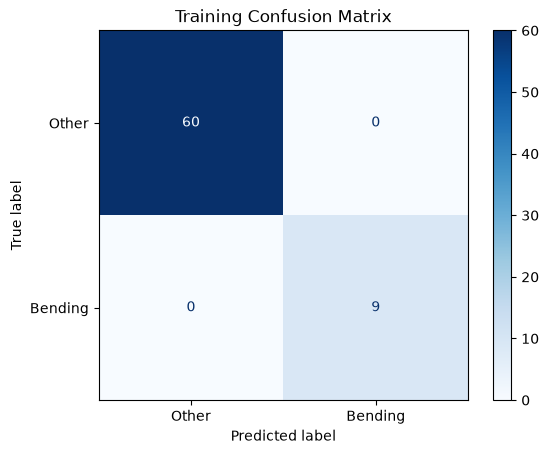

[[60  0]
 [ 0  9]]


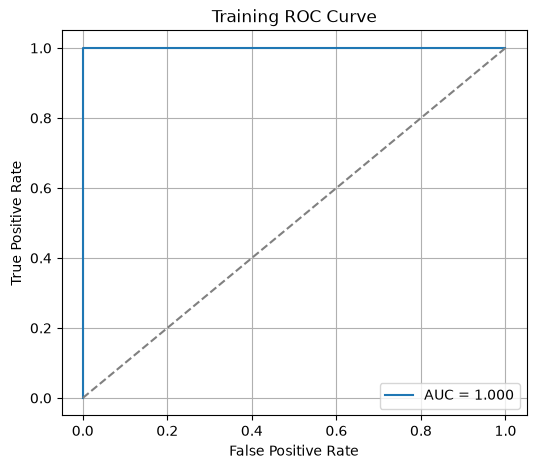

Training AUC: 1.0


In [61]:
train_cm = confusion_matrix(y_train, y_train_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=train_cm,
    display_labels=['Other', 'Bending']
)

display.plot(cmap='Blues')
plt.title('Training Confusion Matrix')
plt.show()

print(train_cm)


fpr, tpr, thresholds = roc_curve(y_train, y_train_prob)
train_auc = roc_auc_score(y_train, y_train_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'AUC = {train_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Training ROC Curve')
plt.legend()
plt.grid()
plt.show()

print("Training AUC:", train_auc)

In [62]:
import statsmodels.api as sm

X_selected = X_train[selected_features]
X_selected = sm.add_constant(X_selected)

logit_model = sm.Logit(y_train, X_selected)

logit_result = logit_model.fit(
    method='lbfgs',
    maxiter=200,
    disp=False
)

model_results = pd.DataFrame({
    'Coefficient': logit_result.params,
    'p-value': logit_result.pvalues
})

model_results

,Coefficient,p-value
const,-68.271126,0.993203
mean5_part3,-26.446788,0.996900
1st_quart5_part3,33.165807,0.996640
std3_part16,-15.978680,0.994831


The classifier correctly classified all 69 training instances. The confusion matrix contains 60 correctly classified other activities and 9 correctly classified bending activities, with no errors. The training accuracy and AUC were both 1.0.
Although the model classified the training data perfectly, the coefficients are large and their p-values are close to 1. This suggests that the logistic regression parameter estimates are unstable because the classes are completely separated.

2a. v.

In [63]:
def make_test_data(l):
    rows = []
    labels = []

    for file in test_files:
        features = extract_l_parts(file, l)
        rows.append(features)

        if file.parent.name in ['bending1', 'bending2']:
            labels.append(1)
        else:
            labels.append(0)

    X = pd.DataFrame(rows)
    y = np.array(labels)

    return X, y

In [64]:
X_test, y_test = make_test_data(best_l)

# Keep the columns in the same order as the training data
X_test = X_test[X_train.columns]

y_test_pred = best_selector.predict(X_test)
y_test_prob = best_selector.predict_proba(X_test)[:, 1]

test_accuracy = accuracy_score(y_test, y_test_pred)

print("Testing instances:", len(y_test))
print("Testing accuracy:", test_accuracy)
print("Cross-validation accuracy:", best_row['CV Accuracy'])

Testing instances: 19
Testing accuracy: 0.8947368421052632
Cross-validation accuracy: 1.0


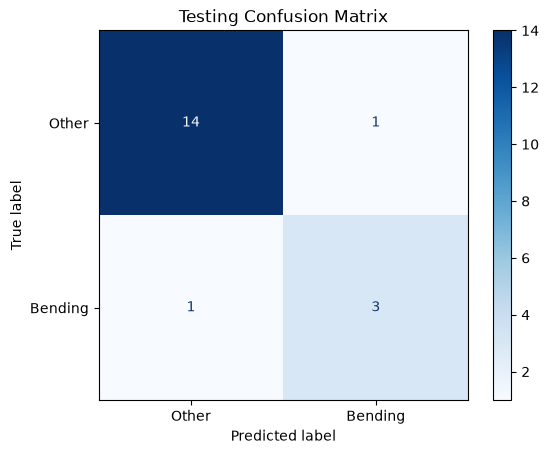

[[14  1]
 [ 1  3]]


In [65]:
test_cm = confusion_matrix(y_test, y_test_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=['Other', 'Bending']
)

display.plot(cmap='Blues')
plt.title('Testing Confusion Matrix')
plt.show()

print(test_cm)

The classifier correctly classified 17 of the 19 test instances, giving a test accuracy of 89.47%. It misclassified one bending instance and one non-bending instance. The test accuracy is lower than the cross-validation accuracy of 100%. Therefore, the cross-validation result slightly overestimated the model's performance on unseen data.

2a. vi.

Yes, the classes appear to be well-separated. The model achieved 100% training and cross-validation accuracy, and the training AUC was also 1.0. This causes instability in logistic regression because the coefficients can continue increasing while separating the two classes. The large coefficients and unreliable p-values obtained previously are evidence of this problem.

2a. vii.

In [66]:
rng = np.random.default_rng(42)

bending_indices = np.where(y_train == 1)[0]
other_indices = np.where(y_train == 0)[0]

selected_other_indices = rng.choice(
    other_indices,
    size=len(bending_indices),
    replace=False
)

sample_indices = np.concatenate([
    bending_indices,
    selected_other_indices
])

X_sample = X_train.iloc[sample_indices][selected_features]
y_sample = y_train[sample_indices]

print("Bending instances:", sum(y_sample == 1))
print("Other instances:", sum(y_sample == 0))

case_model = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(
        C=1000000,
        max_iter=2000
    ))
])

case_model.fit(X_sample, y_sample)

Bending instances: 9
Other instances: 9


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['mean5_part3','1st_quart5_part3','std3_part16']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [67]:
original_proportion = y_train.mean()
sample_proportion = y_sample.mean()

adjustment = (
    np.log(original_proportion / (1 - original_proportion))
    - np.log(sample_proportion / (1 - sample_proportion))
)

old_intercept = case_model.named_steps['model'].intercept_[0]

case_model.named_steps['model'].intercept_[0] += adjustment

new_intercept = case_model.named_steps['model'].intercept_[0]

print("Original bending proportion:", original_proportion)
print("Sample bending proportion:", sample_proportion)
print("Old intercept:", old_intercept)
print("Adjusted intercept:", new_intercept)

Original bending proportion: 0.13043478260869565
Sample bending proportion: 0.5
Old intercept: -2.4792711758530834
Adjusted intercept: -4.376391160738965


Training accuracy: 1.0
[[60  0]
 [ 0  9]]


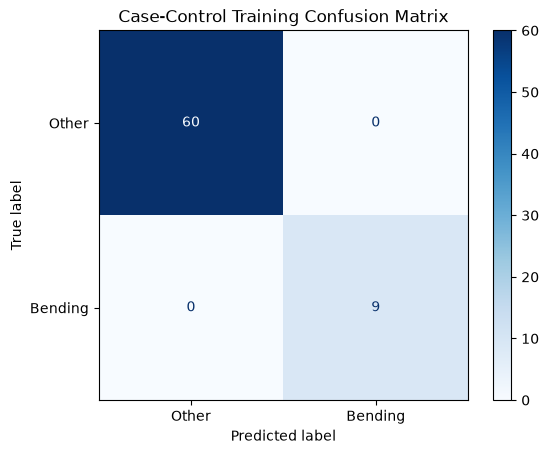

In [68]:
X_case = X_train[selected_features]

case_pred = case_model.predict(X_case)
case_prob = case_model.predict_proba(X_case)[:, 1]

case_accuracy = accuracy_score(y_train, case_pred)
case_cm = confusion_matrix(y_train, case_pred)

print("Training accuracy:", case_accuracy)
print(case_cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=case_cm,
    display_labels=['Other', 'Bending']
)

display.plot(cmap='Blues')
plt.title('Case-Control Training Confusion Matrix')
plt.show()

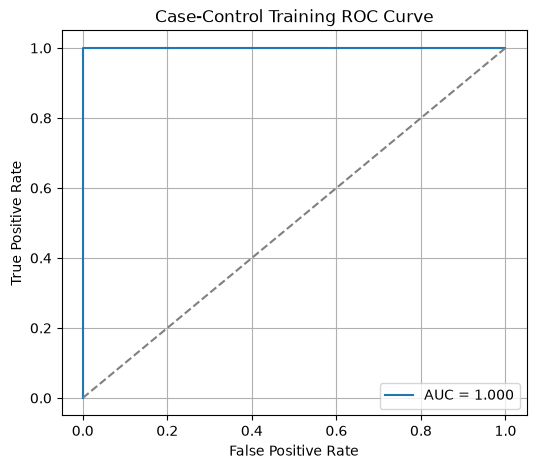

Case-control AUC: 1.0


In [69]:
case_fpr, case_tpr, thresholds = roc_curve(y_train, case_prob)
case_auc = roc_auc_score(y_train, case_prob)

plt.figure(figsize=(6, 5))
plt.plot(case_fpr, case_tpr, label=f'AUC = {case_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Case-Control Training ROC Curve')
plt.legend()
plt.grid()
plt.show()

print("Case-control AUC:", case_auc)

The training data is imbalanced because it contains 60 other activity instances and only 9 bending instances. Case control sampling created a balanced sample containing 9 instances from each class.
The intercept was adjusted from -2.4793 to -4.3764 to account for the original class proportions. The adjusted model correctly classified all training instances and achieved an AUC of 1.0.

2b. i.

In [70]:
from sklearn.model_selection import GridSearchCV

C_values = np.logspace(-4, 4, 20)

l1_results = []
l1_models = {}

for l in range(1, 21):
    X, y = make_training_data(l)

    l1_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(
        solver='liblinear',
        l1_ratio=1,
        max_iter=2000
    ))
])

    grid = GridSearchCV(
        estimator=l1_pipeline,
        param_grid={'model__C': C_values},
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    grid.fit(X, y)

    l1_results.append({
        'l': l,
        'C': grid.best_params_['model__C'],
        'CV Accuracy': grid.best_score_
    })

    l1_models[l] = grid.best_estimator_

    print(
        "l =", l,
        "| C =", round(grid.best_params_['model__C'], 4),
        "| CV Accuracy =", round(grid.best_score_, 4)
    )

l = 1 | C = 545.5595 | CV Accuracy = 0.9857
l = 2 | C = 11.2884 | CV Accuracy = 0.9714
l = 3 | C = 0.2336 | CV Accuracy = 0.9571
l = 4 | C = 1.6238 | CV Accuracy = 0.9714
l = 5 | C = 0.6158 | CV Accuracy = 0.9429
l = 6 | C = 4.2813 | CV Accuracy = 0.9429
l = 7 | C = 1438.4499 | CV Accuracy = 0.9429
l = 8 | C = 206.9138 | CV Accuracy = 0.9429
l = 9 | C = 1.6238 | CV Accuracy = 0.9571
l = 10 | C = 206.9138 | CV Accuracy = 0.9714
l = 11 | C = 4.2813 | CV Accuracy = 0.9857
l = 12 | C = 0.6158 | CV Accuracy = 0.9857
l = 13 | C = 1.6238 | CV Accuracy = 0.9714
l = 14 | C = 545.5595 | CV Accuracy = 0.9571
l = 15 | C = 1438.4499 | CV Accuracy = 0.9286
l = 16 | C = 78.476 | CV Accuracy = 0.9571
l = 17 | C = 29.7635 | CV Accuracy = 0.9571
l = 18 | C = 0.6158 | CV Accuracy = 0.9857
l = 19 | C = 0.6158 | CV Accuracy = 0.9714
l = 20 | C = 11.2884 | CV Accuracy = 0.9857


In [71]:
l1_results_table = pd.DataFrame(l1_results)

best_l1_row = l1_results_table.loc[
    l1_results_table['CV Accuracy'].idxmax()
]

best_l1_l = int(best_l1_row['l'])
best_l1_C = best_l1_row['C']
best_l1_accuracy = best_l1_row['CV Accuracy']

print("Best l:", best_l1_l)
print("Best C:", best_l1_C)
print("Best CV accuracy:", best_l1_accuracy)

l1_results_table

Best l: 1
Best C: 545.5594781168514
Best CV accuracy: 0.9857142857142858


,l,C,CV Accuracy
0,1,545.559478,0.985714
1,2,11.288379,0.971429
2,3,0.233572,0.957143
3,4,1.623777,0.971429
4,5,0.615848,0.942857
5,6,4.281332,0.942857
6,7,1438.449888,0.942857
7,8,206.913808,0.942857
8,9,1.623777,0.957143
9,10,206.913808,0.971429


In [72]:
best_l1_model = l1_models[best_l1_l]

X_l1_train, y_l1_train = make_training_data(best_l1_l)

coefficients = best_l1_model.named_steps['model'].coef_[0]

number_of_features = np.sum(coefficients != 0)

print("Number of selected features:", number_of_features)

X_l1_test, y_l1_test = make_test_data(best_l1_l)

# Keep the test columns in the same order
X_l1_test = X_l1_test[X_l1_train.columns]

y_l1_pred = best_l1_model.predict(X_l1_test)

l1_test_accuracy = accuracy_score(y_l1_test, y_l1_pred)
l1_test_error = 1 - l1_test_accuracy

print("Test accuracy:", l1_test_accuracy)
print("Test error:", l1_test_error)

Number of selected features: 16
Test accuracy: 1.0
Test error: 0.0


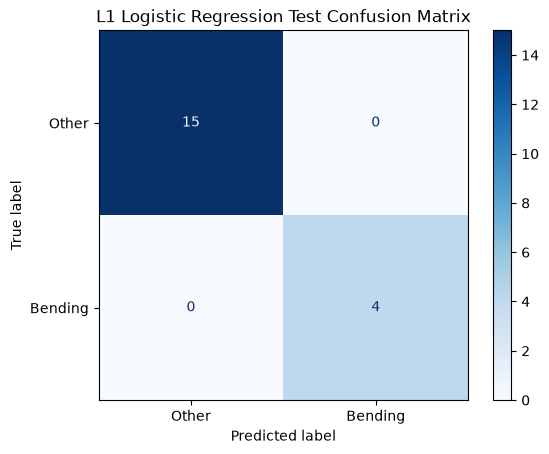

[[15  0]
 [ 0  4]]


In [73]:
l1_cm = confusion_matrix(y_l1_test, y_l1_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=l1_cm,
    display_labels=['Other', 'Bending']
)

display.plot(cmap='Blues')
plt.title('L1 Logistic Regression Test Confusion Matrix')
plt.show()

print(l1_cm)

The best L1-penalized logistic regression model used l=1 and C=545.5595. It retained 15 features and achieved a cross-validation
accuracy of 98.57%. The model correctly classified all 19 test instances, giving a test accuracy of 100% and a test error of 0%.

2b. ii.
The variable-selection model had a slightly higher cross-validation accuracy, but the L1-penalized model performed better on the test set. The L1 model achieved 100% test accuracy, compared with 89.47% for the previous model. L1 regularization was also easier to implement because it performs feature selection automatically by setting some coefficients to zero.

2c. i.


In [74]:
def make_multiclass_data(files, l):
    rows = []
    labels = []

    for file in files:
        features = extract_l_parts(file, l)
        rows.append(features)
        labels.append(file.parent.name)

    X = pd.DataFrame(rows)
    y = np.array(labels)

    return X, y

X_multi_check, y_multi_check = make_multiclass_data(train_files, 1)

pd.Series(y_multi_check).value_counts()

cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64

In [75]:
multi_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

multi_results = []
multi_models = {}

for l in range(1, 21):
    X, y = make_multiclass_data(train_files, l)

    multi_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(
        solver='saga',
        l1_ratio=1,
        max_iter=20000,
        tol=0.001,
        random_state=42
    ))
])

    grid = GridSearchCV(
        estimator=multi_pipeline,
        param_grid={'model__C': C_values},
        cv=multi_cv,
        scoring='accuracy',
        n_jobs=-1
    )

    grid.fit(X, y)

    multi_results.append({
        'l': l,
        'C': grid.best_params_['model__C'],
        'CV Accuracy': grid.best_score_
    })

    multi_models[l] = grid.best_estimator_

    print(
        "l =", l,
        "| C =", round(grid.best_params_['model__C'], 4),
        "| CV Accuracy =", round(grid.best_score_, 4)
    )

l = 1 | C = 4.2813 | CV Accuracy = 0.9142
l = 2 | C = 4.2813 | CV Accuracy = 0.9134
l = 3 | C = 29.7635 | CV Accuracy = 0.8407
l = 4 | C = 29.7635 | CV Accuracy = 0.9126
l = 5 | C = 11.2884 | CV Accuracy = 0.8546
l = 6 | C = 11.2884 | CV Accuracy = 0.8407
l = 7 | C = 545.5595 | CV Accuracy = 0.8407
l = 8 | C = 11.2884 | CV Accuracy = 0.8391
l = 9 | C = 4.2813 | CV Accuracy = 0.8113
l = 10 | C = 29.7635 | CV Accuracy = 0.8252
l = 11 | C = 78.476 | CV Accuracy = 0.8252
l = 12 | C = 4.2813 | CV Accuracy = 0.8105
l = 13 | C = 78.476 | CV Accuracy = 0.8252
l = 14 | C = 1.6238 | CV Accuracy = 0.8391
l = 15 | C = 29.7635 | CV Accuracy = 0.8415
l = 16 | C = 1.6238 | CV Accuracy = 0.8096
l = 17 | C = 1.6238 | CV Accuracy = 0.8113
l = 18 | C = 11.2884 | CV Accuracy = 0.8391
l = 19 | C = 29.7635 | CV Accuracy = 0.7958
l = 20 | C = 29.7635 | CV Accuracy = 0.8105


In [76]:
multi_results_table = pd.DataFrame(multi_results)

best_multi_row = multi_results_table.loc[
    multi_results_table['CV Accuracy'].idxmax()
]

best_multi_l = int(best_multi_row['l'])
best_multi_C = best_multi_row['C']
best_multi_cv_accuracy = best_multi_row['CV Accuracy']

best_multi_model = multi_models[best_multi_l]

print("Best l:", best_multi_l)
print("Best C:", best_multi_C)
print("Best CV accuracy:", best_multi_cv_accuracy)

multi_results_table

Best l: 1
Best C: 4.281332398719396
Best CV accuracy: 0.9142156862745098


,l,C,CV Accuracy
0,1,4.281332,0.914216
1,2,4.281332,0.913399
2,3,29.763514,0.840686
3,4,29.763514,0.912582
4,5,11.288379,0.854575
5,6,11.288379,0.840686
6,7,545.559478,0.840686
7,8,11.288379,0.839052
8,9,4.281332,0.811275
9,10,29.763514,0.825163


In [77]:
X_multi_train, y_multi_train = make_multiclass_data(
    train_files,
    best_multi_l
)

X_multi_test, y_multi_test = make_multiclass_data(
    test_files,
    best_multi_l
)

X_multi_test = X_multi_test[X_multi_train.columns]

y_multi_pred = best_multi_model.predict(X_multi_test)
y_multi_prob = best_multi_model.predict_proba(X_multi_test)

multi_test_accuracy = accuracy_score(
    y_multi_test,
    y_multi_pred
)

multi_test_error = 1 - multi_test_accuracy

print("Test accuracy:", multi_test_accuracy)
print("Test error:", multi_test_error)

Test accuracy: 0.9473684210526315
Test error: 0.052631578947368474


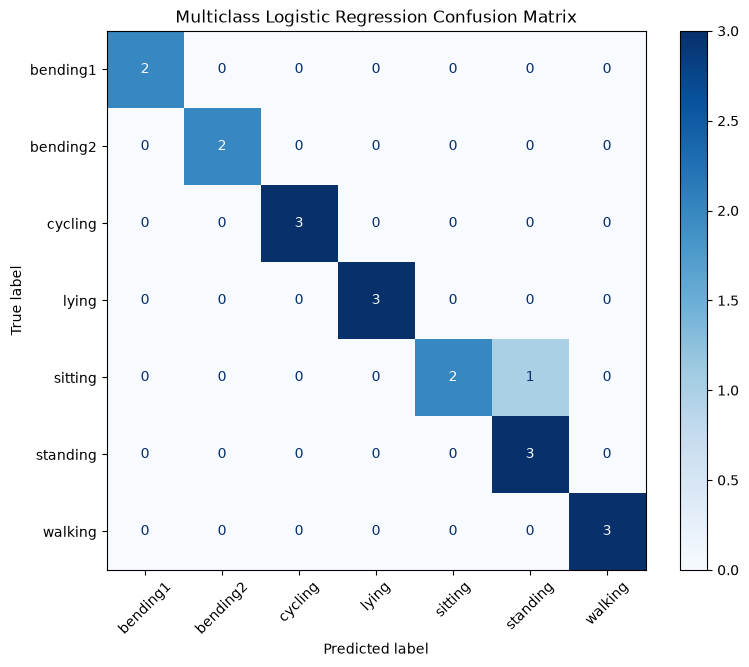

In [78]:
activity_names = best_multi_model.named_steps['model'].classes_

multi_cm = confusion_matrix(
    y_multi_test,
    y_multi_pred,
    labels=activity_names
)

display = ConfusionMatrixDisplay(
    confusion_matrix=multi_cm,
    display_labels=activity_names
)

fig, ax = plt.subplots(figsize=(9, 7))
display.plot(
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)

plt.title('Multiclass Logistic Regression Confusion Matrix')
plt.show()

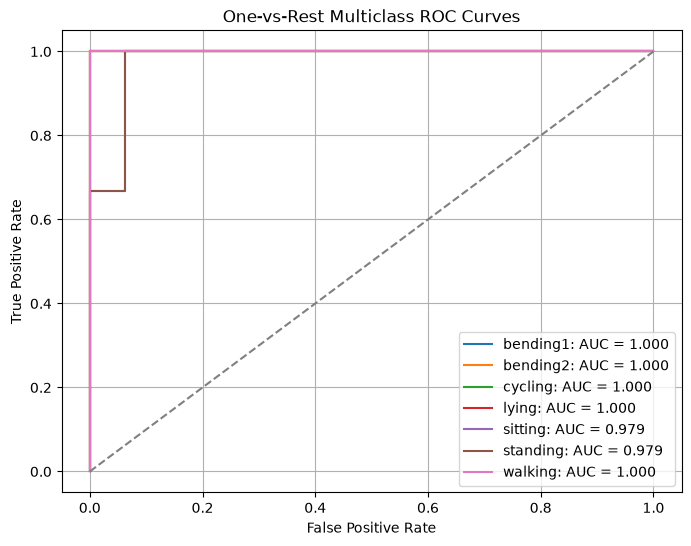

In [79]:
from sklearn.preprocessing import label_binarize

y_multi_binary = label_binarize(
    y_multi_test,
    classes=activity_names
)

plt.figure(figsize=(8, 6))

for i, activity in enumerate(activity_names):
    fpr, tpr, thresholds = roc_curve(
        y_multi_binary[:, i],
        y_multi_prob[:, i]
    )

    auc = roc_auc_score(
        y_multi_binary[:, i],
        y_multi_prob[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{activity}: AUC = {auc:.3f}'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('One-vs-Rest Multiclass ROC Curves')
plt.legend()
plt.grid()
plt.show()

2c. ii.

In [80]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import MinMaxScaler

gaussian_results = []
gaussian_models = {}

for l in range(1, 21):
    X, y = make_multiclass_data(train_files, l)

    gaussian_model = Pipeline([
        ('scale', StandardScaler()),
        ('model', GaussianNB())
    ])

    scores = cross_val_score(
        gaussian_model,
        X,
        y,
        cv=multi_cv,
        scoring='accuracy'
    )

    gaussian_results.append({
        'l': l,
        'CV Accuracy': scores.mean()
    })

    gaussian_models[l] = gaussian_model

    print(
        "l =", l,
        "| CV Accuracy =", round(scores.mean(), 4)
    )

l = 1 | CV Accuracy = 0.826
l = 2 | CV Accuracy = 0.826
l = 3 | CV Accuracy = 0.6675
l = 4 | CV Accuracy = 0.652
l = 5 | CV Accuracy = 0.6078
l = 6 | CV Accuracy = 0.5948
l = 7 | CV Accuracy = 0.6381
l = 8 | CV Accuracy = 0.6503
l = 9 | CV Accuracy = 0.6381
l = 10 | CV Accuracy = 0.6528
l = 11 | CV Accuracy = 0.6217
l = 12 | CV Accuracy = 0.6095
l = 13 | CV Accuracy = 0.5645
l = 14 | CV Accuracy = 0.5645
l = 15 | CV Accuracy = 0.5801
l = 16 | CV Accuracy = 0.5368
l = 17 | CV Accuracy = 0.5654
l = 18 | CV Accuracy = 0.4943
l = 19 | CV Accuracy = 0.5507
l = 20 | CV Accuracy = 0.5515


In [81]:
gaussian_table = pd.DataFrame(gaussian_results)

best_gaussian_row = gaussian_table.loc[
    gaussian_table['CV Accuracy'].idxmax()
]

best_gaussian_l = int(best_gaussian_row['l'])

X_gaussian_train, y_gaussian_train = make_multiclass_data(
    train_files,
    best_gaussian_l
)

X_gaussian_test, y_gaussian_test = make_multiclass_data(
    test_files,
    best_gaussian_l
)

X_gaussian_test = X_gaussian_test[X_gaussian_train.columns]

best_gaussian_model = gaussian_models[best_gaussian_l]
best_gaussian_model.fit(X_gaussian_train, y_gaussian_train)

gaussian_pred = best_gaussian_model.predict(X_gaussian_test)
gaussian_prob = best_gaussian_model.predict_proba(X_gaussian_test)

gaussian_accuracy = accuracy_score(
    y_gaussian_test,
    gaussian_pred
)

print("Best Gaussian l:", best_gaussian_l)
print("Gaussian CV accuracy:", best_gaussian_row['CV Accuracy'])
print("Gaussian test accuracy:", gaussian_accuracy)
print("Gaussian test error:", 1 - gaussian_accuracy)

Best Gaussian l: 2
Gaussian CV accuracy: 0.8259803921568628
Gaussian test accuracy: 0.631578947368421
Gaussian test error: 0.368421052631579


In [82]:
multinomial_results = []
multinomial_models = {}

for l in range(1, 21):
    X, y = make_multiclass_data(train_files, l)

    multinomial_model = Pipeline([
        ('scale', MinMaxScaler(clip=True)),
        ('model', MultinomialNB())
    ])

    scores = cross_val_score(
        multinomial_model,
        X,
        y,
        cv=multi_cv,
        scoring='accuracy'
    )

    multinomial_results.append({
        'l': l,
        'CV Accuracy': scores.mean()
    })

    multinomial_models[l] = multinomial_model

    print(
        "l =", l,
        "| CV Accuracy =", round(scores.mean(), 4)
    )

l = 1 | CV Accuracy = 0.7533
l = 2 | CV Accuracy = 0.7835
l = 3 | CV Accuracy = 0.7386
l = 4 | CV Accuracy = 0.7108
l = 5 | CV Accuracy = 0.6953
l = 6 | CV Accuracy = 0.6953
l = 7 | CV Accuracy = 0.723
l = 8 | CV Accuracy = 0.6667
l = 9 | CV Accuracy = 0.6953
l = 10 | CV Accuracy = 0.7092
l = 11 | CV Accuracy = 0.6667
l = 12 | CV Accuracy = 0.6953
l = 13 | CV Accuracy = 0.6814
l = 14 | CV Accuracy = 0.6806
l = 15 | CV Accuracy = 0.6806
l = 16 | CV Accuracy = 0.652
l = 17 | CV Accuracy = 0.6806
l = 18 | CV Accuracy = 0.6667
l = 19 | CV Accuracy = 0.6797
l = 20 | CV Accuracy = 0.6806


In [83]:
multinomial_table = pd.DataFrame(multinomial_results)

best_multinomial_row = multinomial_table.loc[
    multinomial_table['CV Accuracy'].idxmax()
]

best_multinomial_l = int(best_multinomial_row['l'])

X_multinomial_train, y_multinomial_train = make_multiclass_data(
    train_files,
    best_multinomial_l
)

X_multinomial_test, y_multinomial_test = make_multiclass_data(
    test_files,
    best_multinomial_l
)

X_multinomial_test = X_multinomial_test[
    X_multinomial_train.columns
]

best_multinomial_model = multinomial_models[
    best_multinomial_l
]

best_multinomial_model.fit(
    X_multinomial_train,
    y_multinomial_train
)

multinomial_pred = best_multinomial_model.predict(
    X_multinomial_test
)

multinomial_prob = best_multinomial_model.predict_proba(
    X_multinomial_test
)

multinomial_accuracy = accuracy_score(
    y_multinomial_test,
    multinomial_pred
)

print("Best Multinomial l:", best_multinomial_l)
print(
    "Multinomial CV accuracy:",
    best_multinomial_row['CV Accuracy']
)
print("Multinomial test accuracy:", multinomial_accuracy)
print("Multinomial test error:", 1 - multinomial_accuracy)

Best Multinomial l: 2
Multinomial CV accuracy: 0.7834967320261437
Multinomial test accuracy: 0.7894736842105263
Multinomial test error: 0.21052631578947367


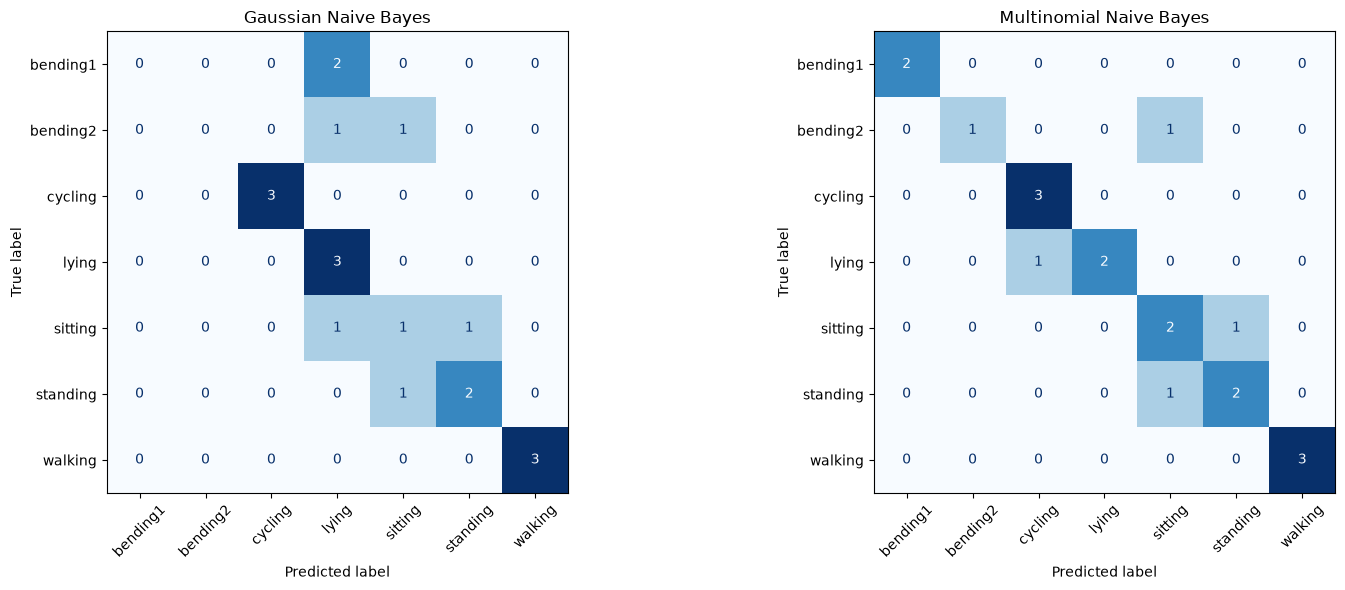

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

gaussian_cm = confusion_matrix(
    y_gaussian_test,
    gaussian_pred,
    labels=activity_names
)

ConfusionMatrixDisplay(
    gaussian_cm,
    display_labels=activity_names
).plot(
    cmap='Blues',
    xticks_rotation=45,
    ax=axes[0],
    colorbar=False
)

axes[0].set_title('Gaussian Naive Bayes')

multinomial_cm = confusion_matrix(
    y_multinomial_test,
    multinomial_pred,
    labels=activity_names
)

ConfusionMatrixDisplay(
    multinomial_cm,
    display_labels=activity_names
).plot(
    cmap='Blues',
    xticks_rotation=45,
    ax=axes[1],
    colorbar=False
)

axes[1].set_title('Multinomial Naive Bayes')

plt.tight_layout()
plt.show()

In [85]:
def plot_multiclass_roc(y_test, probabilities, classes, title):
    y_binary = label_binarize(
        y_test,
        classes=classes
    )

    plt.figure(figsize=(8, 6))

    for i, activity in enumerate(classes):
        fpr, tpr, thresholds = roc_curve(
            y_binary[:, i],
            probabilities[:, i]
        )

        auc = roc_auc_score(
            y_binary[:, i],
            probabilities[:, i]
        )

        plt.plot(
            fpr,
            tpr,
            label=f'{activity}: AUC = {auc:.3f}'
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        color='gray'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

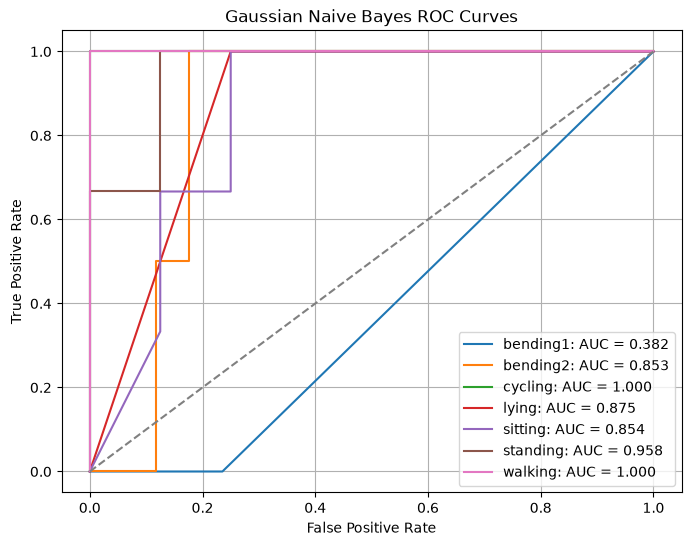

In [86]:
gaussian_classes = best_gaussian_model.named_steps[
    'model'
].classes_

plot_multiclass_roc(
    y_gaussian_test,
    gaussian_prob,
    gaussian_classes,
    'Gaussian Naive Bayes ROC Curves'
)

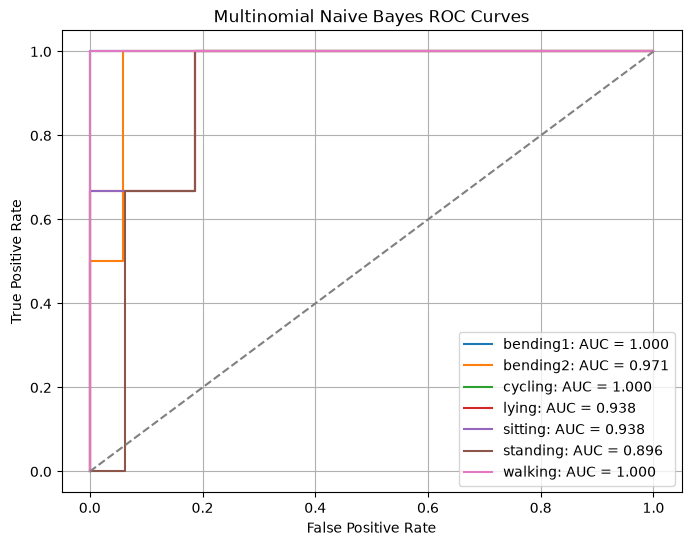

In [87]:
multinomial_classes = best_multinomial_model.named_steps[
    'model'
].classes_

plot_multiclass_roc(
    y_multinomial_test,
    multinomial_prob,
    multinomial_classes,
    'Multinomial Naive Bayes ROC Curves'
)

Both Naive Bayes models selected l=2. Gaussian Naive Bayes achieved a cross-validation accuracy of 82.60% and a test accuracy of 63.16%, giving a test error of 36.84%. It performed poorly on the two bending classes, especially bending1.
Multinomial Naive Bayes achieved a cross-validation accuracy of 78.35% and a test accuracy of 78.95%, giving a test error of 21.05%. It performed better than Gaussian Naive Bayes on the test set.

2c. iii.
L1-penalized multinomial logistic regression performed best, with a test accuracy of 94.74%. Multinomial Naive Bayes was the second-best method with 78.95% accuracy, while Gaussian Naive Bayes had the lowest accuracy at 63.16%.
Therefore, L1-penalized multinomial logistic regression is the best method for multiclass classification on this dataset.

3.

For class $k$, assume

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2)
$$

and let $\pi_k$ be the prior probability of class $k$.

Bayes' theorem assigns $X=x$ to the class with the largest value of

$$
\pi_k \frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$

Taking the logarithm does not change which class has the largest value:

$$
\log(\pi_k)-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
-\frac{1}{2}\log(2\pi).
$$

The term $-\frac{1}{2}\log(2\pi)$ is the same for every class, so it can be removed. Expanding the squared term gives

$$
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
=
-\frac{x^2}{2\sigma_k^2}
+\frac{x\mu_k}{\sigma_k^2}
-\frac{\mu_k^2}{2\sigma_k^2}.
$$

Therefore, the discriminant function is

$$
\delta_k(x)=
-\frac{x^2}{2\sigma_k^2}
+\frac{x\mu_k}{\sigma_k^2}
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac{1}{2}\log(\sigma_k^2)
+\log(\pi_k).
$$

The classifier assigns $x$ to the class with the largest $\delta_k(x)$. Since this function contains an $x^2$ term, the decision boundary between two classes is quadratic. This is why the method is called **Quadratic Discriminant Analysis**.

4.

Let $Y=\text{Yes}$ represent a company issuing a dividend. The given values are

$$
\pi_{\text{Yes}}=0.8, \qquad \pi_{\text{No}}=0.2
$$

$$
\mu_{\text{Yes}}=10, \qquad
\mu_{\text{No}}=0, \qquad
\sigma^2=36.
$$

Using Bayes' theorem for a company with $X=4$,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{
0.8\exp\left(-\frac{(4-10)^2}{2(36)}\right)
}{
0.8\exp\left(-\frac{(4-10)^2}{2(36)}\right)
+
0.2\exp\left(-\frac{(4-0)^2}{2(36)}\right)
}.
$$

Therefore,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{0.8e^{-0.5}}
{0.8e^{-0.5}+0.2e^{-2/9}}
\approx 0.752.
$$

Thus, the probability that the company will issue a dividend is
approximately **75.2%**.